# **1. Q-Table**
- Q는 "현재 상태에서 이 행동을 했을 때 앞으로 얼마나 유리한가"를 나타내는 행동가치
- Q-Table은 이 값을 표 형태로 저장
- Q-Table은 정답표가 아님. 에이전트가 보상을 경험하며 채우고 수정하는 표

### Q-Table의 한계
- 로봇은 거리, 속도 , 방향 등 연속적인 숫자를 받음
- 상태를 세밀하게 구분하면 조합이 매우 큼. 예) 센서 3개를 각각 100단계로 구분하고 행동이 4개라면 100 * 100 * 100 * 4  = 4000000개의 Q값이 필요
- 상태마다 숫자를 저장한느 대신 상태 -> 신경망 -> 각 행동의 Q값이라는 관계를 학습
    - 처음 보는 상태도 비슷한 학습 경험을 활용해 Q깂을 예측 -> 함수 근사

> 신경망이 언제나 정확한 것은 아님. 학습 경험이 부족하거나 새로운 상황이 너무 다르면 잘못 예측할 수 있음

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

small = np.zeros((5, 2))
large_count = 100 ** 3 * 4
print('작은 미로 Q-Table 크기:', small.shape, '→', small.size, '개')
print('센서 3개를 100단계로 구분할 때:', f'{large_count:,}', '개')
print('float32로 저장할 때 약:', round(large_count * 4 / 1024**2, 2), 'MiB')

작은 미로 Q-Table 크기: (5, 2) → 10 개
센서 3개를 100단계로 구분할 때: 4,000,000 개
float32로 저장할 때 약: 15.26 MiB


In [3]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [4]:
x = torch.arange(1, 6, dtype=torch.float32).unsqueeze(1)
y = x / 6.0
model = nn.Linear(1, 1)
optimizer = optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    prediction = model(x)
    loss = ((prediction - y) ** 2).mean()
    optimizer.zero_grad() # 미분값 초기화
    loss.backward()
    optimizer.step()

In [5]:
print('w, b: ', model.weight.item(), model.bias.item()),
print('상태 2.5의 예측 가치: ', model(torch.tensor([[2.5]])).item())

w, b:  0.16890689730644226 -0.008087950758635998
상태 2.5의 예측 가치:  0.4141792953014374


# **2. DQN**

### DQN이 단순한 신경망 하나가 아닌 이유
- 신경망에 상태를 넣고  Q값만 예측할 수 없음
- 강화학습 데이터는 일반적인 사진 분류 데이터와 다르게 시간 순서대로 서로 비슷한 경험이 연속해서 발생
- 학습 목표를 만드는 데 사용하는 Q값도 신경망이 추정하므로 목표 자체가 계속 바뀜

1. Q-Network: 현재 상태를 보고 각 행동의 Q점수를 예측. 예) [왼쪽=12.1, 오른쪽=15.4]라면 오른쪽이 더 좋다고 판단
2. Experience Replay(경험 재생): 상태, 행동, 보상, 다음 상태, 종료 여부를 메모리에 모아 둠. 학습할 때는 최근 경험 하나만 쓰지 않고 경험을 무작위로 섞어 뽑음. 연속 경험 사이의 상관성을 완화하고 경험을 재사용할 수 있음
3. Target Network(타깃 신경망): 학습하는 네트워크와 별도로 목표값 계산용 네트워크를 둠. 목표값이 매번 너무 급격히 움직이지 않도록 일정 주기마다 학습 네트워크의 가중치를 복사함

> Target Network는 잠시 고정된 정답지 역할.  Replay Buffer는 과거 문제를 섞어 복습하는 문제은행과 비슷

> 타깃 신경망이 실제 정답을 아는 것은 아님. 역시 추정값을 제공할 뿐임


----------------------------------------------------
# 여기서부터 빠진 구간

### 지도학습과 DQN 학습의 차이
1. 위 지도학습 예시
- 입력: 숫자 x
- 목표값: 미리 정한 x/6
- 출력: 예측 숫자 1개
- 학습: 손실 -> 역전파 -> 가중치 수정

2. DQN
- 입력: 환경에서 관측한 상태
- 목표값: 보상 + 할인된 다음 상태 가치
- 출력: 각 이산 행동의 Q값
- 학습: 손실 -> 역전파 -> 가중치 수정

> 이산 행동: 에이전트가 선택할 수 있는 행동이 정해진 개수로 구분되어 있는 것

> 연속 행동: 일정한 범위 안에서 연속적인 값을 선택하는 행동. 예) 자동차 핸들 -2.0 ~ 2.0 조절

> Q값: 현재 상태에서 특정 행동을 선택했을 때 앞으로 얻을 것으로 기대되는 누적 보상

### CartPole
- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모름
- 환경이 제공하는 관측값
    - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
    - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
    - 막대 각도: 막대가 어느 쪽으로 얼마나 기울어졌는가
    - 막대 각속도: 기울기가 얼마나 빨리 변하는가
- 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓음. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라 장기적으로 균형을 오래 유지하는 행동
- reset(): 새 시도를 시작
- step(action): 행동 후 (관측, 보상, terminated, truncated, info)를 반환
    - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
    - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

```
pip install gymnasium
```

```
이렇게 설치하고 진행하면 시각화 할 수 있음  
python -m pip install swig
python -m pip install "gymnasium[box2d]"


probe = gym.make('CartPole-v1', render_mode="human") 
```

In [6]:
import gymnasium as gym

In [7]:
# CartPole-v1 환경 생성
probe = gym.make('CartPole-v1')  # render_mode="human" 이건 시각화 할 수 있음

# 난수 시드를 고정하고 환경을 초기화
# obs: 초기 관측값, info: 추가 정보
obs, info = probe.reset(seed=SEED)

# obs: [카트 위치, 카트 속도, 막대 각도, 막대 각속도]
# observation_space: 관측값의 형태, 자료형, 각 성분의 허용 범위를 정의
# Box 공간의 범위는 성분에 따라 무한대일 수도 있음
print('관측: ', obs, ' | 관측 공간: ', probe.observation_space)

# 행동 공간: Discrete(2)
# 0은 카트를 왼쪽으로, 1은 오른쪽으로 밀기
print('행동 공간: ', probe.action_space)

# 행동 0(왼쪽으로 밀기)을 수행하고 한 단계 진행
# next_obs: 행동 후 관측값
# reward: 해당 단계의 보상
# terminated: 실패 조건 충족 등으로 에피소드가 종료되었는지 여부
# truncated: 시간 제한 등으로 에피소드가 중단되었는지 여부
# info: 추가 정보
next_obs, reward, terminated, truncated, info = probe.step(0)

# 보상과 종료·중단 여부 출력
print('한 단계 결과: ', reward, terminated, truncated)

# 환경에서 사용하는 자원 해제
# probe.close()

관측:  [-0.03210652  0.01399132 -0.00327316 -0.01294995]  | 관측 공간:  Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간:  Discrete(2)
한 단계 결과:  1.0 False False


### Replay Buffer
- 경험 저장소. 예) (상태 4개, 오른쪽, +1, 다음 상태 4개, False)

In [8]:
class ReplayBuffer:
    def __init__(self, capacity=30000):
        # 최대 capacity개를 저장하며, 초과하면 가장 오래된 경험부터 삭제
        self.data = deque(maxlen=capacity)
    def add(self, s, a, r, ns, terminated):
        # 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 하나의 경험으로 저장
        self.data.append((s, a, r, ns, terminated))
    def sample(self, batch_size):
        # 저장된 경험에서 batch_size개를 중복 없이 무작위 추출
        batch = random.sample(self.data, batch_size)
        # 추출한 경험들을 상태, 행동, 보상, 다음 상태, 종료 여부로 분리
        s, a, r, ns, d = zip(*batch)
        # 각 항목을 DEVICE의 텐서로 변환
        # s, ns: [batch_size, 상태 차원], a, r, d: [batch_size, 1]
        # a는 정수 인덱스, d는 종료 여부를 나타내는 0.0 또는 1.0
        return (torch.as_tensor(np.asarray(s),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1),
                torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1),
                torch.as_tensor(np.asarray(ns),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(d,dtype=torch.float32,device=DEVICE).unsqueeze(1))
    def __len__(self):
        # 현재 저장된 경험 개수 반환
        return len(self.data)

In [9]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim=4, actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, actions)
        )

    def forward(self, x):
        return self.net(x)

In [10]:
q_test = QNetwork().to(DEVICE)
q_test

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [11]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


```
현재 상태에서 오른쪽 행동의 신경망 예측이 Q=4라고 가정
행동 후 보상 +1을 받았고, 타깃 신경망이 다음 상태의 최고 Q를 6이라고 예측했다면,
할인율 0.9에서 목표는 1+0.9*6=6.4

현재 예측 4와 목표 6.4사이의 차이가 있으므로, 신경망 가중치를 조금 수정해 오른쪽 행동의 Q예측이 목표에 가까워지게 함
```

In [12]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
    # 리플레이 버퍼에서 학습에 사용할 경험을 무작위 추출
    states, actions, rewards, next_states, terminated = buffer.sample(batch_size)
    # gather: 신경망이 출력한 여러 행동 점수 중 실제로 선택했던 행동의 점수만 추출
    # online(states)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만듦
    chosen_q = online(states).gather(1, actions)
    # TD 목표값 계산에는 기울기를 추적하지 않음
    with torch.no_grad():
        if double:
            # Double DQN: 온라인 신경망으로 행동을 선택하고 타깃 신경망으로 평가
            # 다음 상태에서 Q값이 가장 큰 행동의 인덱스 선택
            next_actions = online(next_states).argmax(dim=1, keepdim=True)
            # 선택한 행동의 Q값을 타깃 신경망에서 추출
            next_q = target(next_states).gather(1, next_actions)

        else:
            # 일반 DQN: 타깃 신경망에서 다음 상태의 최대 Q값을 구함
            next_q = target(next_states).max(dim=1, keepdim=True).values
            # TD 목표값은 아래에서 두 방식에 공통으로 계산
        # 종료된 상태는 미래 가치를 제외하고 보상만 목표값으로 사용
        targets = rewards + gamma * (1-terminated) * next_q
    # 예측 Q값과 TD 목표값 사이의 Smooth L1 손실 계산
    loss = nn.functional.smooth_l1_loss(chosen_q, targets)
    # 이전에 누적된 기울기 초기화
    optimizer.zero_grad()
    # 역전파로 온라인 신경망의 기울기 계산
    loss.backward()
    # 기울기의 전체 노름을 최대 10으로 제한하여 과도한 업데이트 방지
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    # 계산된 기울기로 온라인 신경망의 파라미터 업데이트
    optimizer.step()
    # 손실을 파이썬 실수로 반환
    return float(loss.item())

- DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기

1. 구현 요구사항
    - CartPole-v1 환경 생성
    - Online Network와 Target Network 생성
    - Adam 옵티마이저, Replay Buffer 초기화
    - 초기에는 무작위 행동을 많이 선택하도록 구현
    - 학습이 진행될수록 ε값을 감소
    - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
    - 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 Replay Buffer에 저장
    - Replay Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
    - 4스탭마다 dqn_update() tlfgod
    - 500 스탭마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
    - 총 250개 에피소드 학습
    - 에피소드별 누적 보상 저장
    - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력

3. 학습 결과 시각화
    - 에피소드별 누적 보상
    - 최근 20개 에피소드의 이동평균 보상

------------------------------------------
# 빠진 구간

In [13]:

def train_cartpole(episodes=250, double=False, seed=2026):
    # 난수 고정
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)

    # Online Network와 Target Network 생성
    online = QNetwork().to(DEVICE)
    target = QNetwork().to(DEVICE)
    target.load_state_dict(online.state_dict()) # Online의 가중치를 Target에 복사
    target.eval()

    optimizer = optim.Adam(online.parameters(), lr=5e-4)
    replay = ReplayBuffer() # 경험 재생 버퍼
    returns = [] # 에피소드별 총 보상
    losses = [] # 학습 손실값
    steps = 0 # 전체 스텝 수

    for episode in range(episodes):
        state, _ = env.reset(seed=seed+episode)
        total = 0.0

        for t in range(500):
            # Epsilon-Greedy: 초반에는 탐험, 이후 점차 활용 비율 증가
            epsilon = max(0.05, 1.0-steps/12000)

            if random.random() < epsilon:
                action = env.action_space.sample() # 탐험: 무작위 행동 선택
            else:
                # 활용: Online Network에서 Q값이 가장 높은 행동 선택
                with torch.no_grad():
                    tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                    action = int(online(tensor).argmax(dim=1).item())

            # 행동 실행 및 다음 상태, 보상, 종료 여부 반환
            next_state, reward, terminated, truncated, _ = env.step(action)

            replay.add(state, action, reward, next_state, terminated) # 경험 저장
            state = next_state
            total += reward
            steps += 1

            # 경험이 1000개 이상 쌓이면 4스텝마다 신경망 학습
            if len(replay) >= 1000 and steps % 4 == 0:
                losses.append(dqn_update(online, target, replay, optimizer, double=double))

            # 500스텝마다 Online의 가중치를 Target에 복사
            if steps % 500 == 0:
                target.load_state_dict(online.state_dict())

            if terminated or truncated: break # 에피소드 종료

        returns.append(total)

        # 50에피소드마다 최근 20에피소드의 평균 보상 출력
        if (episode+1) % 50 == 0:
            print(f'{episode+1:3d}회 | 최근 20회 평균 보상: {np.mean(returns[-20:]):.1f}')

    env.close()
    return online, returns, losses # 학습된 모델, 보상 기록, 손실 기록


In [14]:
trained_q, train_returns, train_losses = train_cartpole(episodes=250)

 50회 | 최근 20회 평균 보상: 26.6
100회 | 최근 20회 평균 보상: 22.5
150회 | 최근 20회 평균 보상: 31.5
200회 | 최근 20회 평균 보상: 93.0
250회 | 최근 20회 평균 보상: 200.6


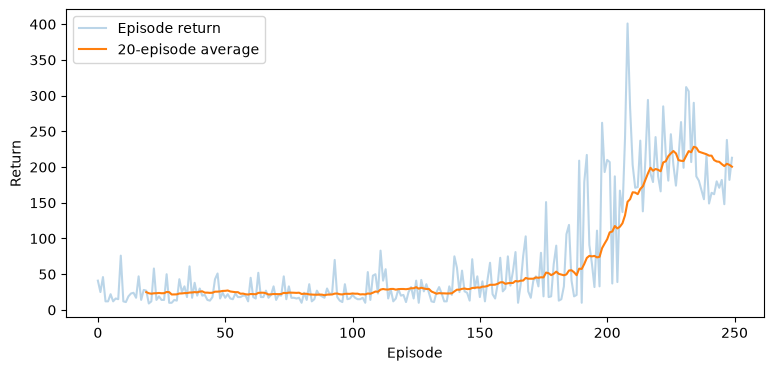

In [15]:
# 학습이 불안정하면 에피소드 수, 탐험률, 학습률 등 확인
plt.figure(figsize=(9,4))
plt.plot(train_returns,alpha=.3,label='Episode return')
if len(train_returns)>=20:
    plt.plot(np.arange(19,len(train_returns)),np.convolve(train_returns,np.ones(20)/20,'valid'),label='20-episode average')
plt.xlabel('Episode');plt.ylabel('Return');plt.legend();plt.show()

In [16]:
def evaluate_cartpole(model, episodes=10, seed=9000):
    env = gym.make('CartPole-v1')
    scores = []
    model.eval()

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep) #  평가마다 초기상태 다르게
        total = 0
        while True:
            with torch.no_grad():
                # 관측 4개를 (1, 4) 형태로 만듦
                x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                action = int(model(x).argmax(dim=1).item())
            state, r, terminated, truncated, _ = env.step(action)
            total += r
            if terminated or truncated: break
        scores.append(total)
    env.close()
    return scores

In [17]:
scores = evaluate_cartpole(trained_q)
print("평가 점수: ", scores)
print(f"평균={np.mean(scores):.1f}, 표준편차={np.std(scores):.1f}")

평가 점수:  [221.0, 295.0, 210.0, 208.0, 245.0, 310.0, 237.0, 243.0, 227.0, 210.0]
평균=240.6, 표준편차=33.6


> 학습이 진행될수록 에피소드별 누적 보상(return)이 증가하고, 높은 보상이 안정적으로 유지된다면 학습이 잘되고 있다고 판단

> 학습 그래프가 좋아 보이는 것과 실제 모델이 잘 학습된 것은 다름 -> evaluate_cartpole()로 평가

### Cartpole에서 학습이 잘 되고 있는지 확인
- 매 스텝마다 일반적으로 보상 +1
- 막대가 넘어지거나 수레가 허용 위치를 벗어나면 종료
- 최대 500 스텝까지 진행
- 한 에피소드의 최대 누적 보상은 500점

```
10 ~ 30: 거의 학습되지 않은 수준
30 ~ 100: 일부 행동을 학습했을 가능성
100 ~ 200: 균형 유지 능력이 개선되는 단계
200 ~ 400: 좋은 성능
400 ~ : 최대 성능
```

> DQN 학습이 잘 되었다는 것은 Loss가 작아지는 것만을 의미하진 않음. 가장 중요한 것은 학습된 신경망이 실제 환경에서 좋은 행동을 선택하고, 여러 번 평가했을 때 누적 보상을 안정적으로 얻는 것

# **3. Policy Gradient**
```
달리는 캐릭터 앞에 장애물이 있음(가능 행동 0=대기, 1= 점프)
- 학습 전: 점프 50%, 대기 50% -> 결과는 아직 잘 모름
- 점프해서 장애물을 피함 -> 좋은 결과를 경험
- 비슷한 상황을 반복 학습한 뒤 -> 점프 90%, 대기 10%
```

> 정책은 '항상 점프'가 아님. 장애물이 멀면 대기가 좋을 수 있고, 가까우면 점프가 좋을 수 있음. 따라서 신경망은 현재 상태를 입력 받아 행동별 확률을 출력

π(a|s): 상태 s일 때 행동 a를 선택할 확률
θ: 신경망의 가중치, 즉 학습하면서 바뀌는 숫자들
πθ(a|s): 신경망 가중치 θ가 정하는 행동 확률

> 확률 90%는 90%의 성공률과 다름. 점프를 선택할 확률일 뿐

In [18]:
before = np.array([0.5, 0.5])
after  = np.array([0.1, 0.9])
for name, p in [('학습 전', before), ('학습 후(가상)', after)]:
    print(f'{name}: 대기 {p[0]*100:.0f}%, 점프 {p[1]*100:.0f}%, 합계 {p.sum():.1f}')

학습 전: 대기 50%, 점프 50%, 합계 1.0
학습 후(가상): 대기 10%, 점프 90%, 합계 1.0


### DQN vs 정책 신경망
- DQN: 행동의 예상 점수를 계산하고 높은 쪽으로 고름. 예) 현재 상태 -> 신경망 -> [대기 Q=2, 점프=6]
- 정책 신경망: 행동을 선택할 확률을 계산하고 그 확률에 따라 행동을 뽑을 수 있음. 예) 현재 상태 -> 신경망 -> [대기 20%, 점프 80%]

> 둘 다 신경망 가중치를 실제로 학습. 다만 출력의 의미와  학습 목표가 다름. DQN에서의 ε-greedy는 탐험을 위한 별도 규칙이지만, 정책 신경망은 행동 확률 자체를 배움

> 정책 기반이라고 해서 무작위 행동만 하는 것은 아님. 평가할 때는 가장 확률이 높은 행동을 선택하기도 함

### 학습의 순서
1. 현재 상황 관측. 예) 장애물 거리, 캐릭터 속도
2. 정책 신경망이 확률 계산. 예) 대기 40%, 점프 60%
3. 행동 선택. 예) 이번에는 점프
4. 실행. 예) 장애물을 피해서 보상 + 10
5. 경험으로 학습 신호 만들기. 예) 이번 행동이 좋은 결과와 연결됐다는 정보
6. 손실함수 계산 / 역잔파 / 가중치 수정. 예) 비슷한 상황에서 점프 확률을 높이는 방향으로 학습할 수 있음
7. 다시 게임 실행. 예) 많은 경험을 반복하며 정책 개선

In [19]:
from torch.distributions import Categorical, Normal

In [20]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim = 4, n_actions = 2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),
            nn.Tanh(),
            nn.Linear(64, n_actions)
        )

    def forward(self, x):
        return self.net(x)

In [21]:
policy_demo = PolicyNet().to(DEVICE)
state_demo = torch.tensor([[0.0, 0.1, 0.02, -0.03]], dtype=torch.float32, device=DEVICE)
logits = policy_demo(state_demo)

# Categorical: 0, 1 처럼 이산 행동의 확률 분포
# Normal: 연속 행동의 정규 분포
# logits는 확률 이전의 점수 > softmax를 적용하면 합계가 1인 확률 > Categorical로 실제 행동을 추첨
dist = Categorical(logits=logits)
a = dist.sample()
print('logits: ', logits.detach().cpu().numpy())
print('확률: ', dist.probs.detach().cpu().numpy())
print('행동: ', a.item(), 'log_prob: ', dist.log_prob(a).item())

logits:  [[ 0.2250176  -0.02445354]]
확률:  [[0.56204635 0.43795368]]
행동:  0 log_prob:  -0.5761709809303284


### 한 에피소드가 끝난 뒤 학습
- 순서: reset() -> 행동 샘플 -> step -> (log_prob, reward) 저장 -> 종료 -> G_t 계산 -> loss.backward() -> optimizer.step()
- 미래 보상을 실제 에피소드 결과에서 계산하므로 신경망으로 다음 상태 가치를 부트스트랩하지 않음
- 에피소드 전체를 기다려야 하고 결과 변동이 큰 편
- 예) 보상이 [1, 1, 1], γ=0.9이면 마지막 시점 G₂ = 1, G₁ = 1 + 0.9 * 1 = 1.9, G₀ = 1 + 0.9 * 1.9 = 2.71
- 첫 행동은 이후 보상까지 반영

In [22]:
def discounted_returns(rewards,gamma=0.99):
    out=[]; running=0.0
    for r in reversed(rewards):
        running=float(r)+gamma*running
        out.append(running)
    return list(reversed(out))
print('예시:',discounted_returns([1,1,1],gamma=0.9))

예시: [2.71, 1.9, 1.0]


In [23]:
# # 내가 한거

# def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr = 1e-3):
#     torch.manual_seed(seed)
#     env = gym.make('CartPole-v1')
#     net = PolicyNet().to(DEVICE)
#     optimizer = optim.Adam(net.parameters(), lr = lr)
#     scores = []

#     for ep in range(episodes):
#         state, _ = env.reset(seed = seed + ep)
#         logps = []
#         rewards = []

#         for t in range(500):

# # 
# # 1. tensor로 저장
# # 2. Categorical 사용
# # 3. sample 뽑기
# # 4. 4개의 상태 저장
# # 5. 학습

# # """
#             # 1. tensor로 저장
#             state_tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)

#             # 2. Categorical 사용 
#             logits = net(state_tensor)
#             dist = Categorical(logits=logits)

#             # 3. sample 뽑기
#             sample = dist.sample()

#             logps.append(dist.log_prob(sample)) # 지피티가 도와줌

#             # 4. 4개의 상태 저장
#             while True:
#                 with torch.no_grad():
#                     # 관측 4개를 (1, 4) 형태로 만듦
#                     action = int(model(state_tensor).argmax(dim=1).item())
#                 state, r, terminated, truncated, _ = env.step(action)
#                 total += r
#                 if terminated or truncated: break
            

#             # 5. 학습
#             def discounted_returns(rewards,gamma=0.99):
#                 out=[]; running=0.0
#                 for r in reversed(rewards):
#                     running=float(r)+gamma*running
#                     out.append(running)
#                 return list(reversed(out))


#     env.close()
#     return net, scores

In [24]:
"""
                        DQN                     REINFORCE
저장:               Replay Buffer          현재 한 판의 logps, rewards
학습:               일정 스탭마다               한 판 종료 후
방식:               Q값 예측 개선            행동 선택 확률 개선
과거 경험 재사용:        가능                     하지 않은
"""

def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr = 1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr = lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed = seed + ep)
        logps = []
        rewards = []

        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            dist = Categorical(logits=net(x))
            a = dist.sample()
            next_state, reward, terminated, truncated, _ = env.step(int(a.item()))
            
            # 로그 확률을 사용하면 선택한 행동의 확률을 높이거나 낮추기 위한 신경망의 기울기를 계산하기 편리하기 때문
            logps.append(dist.log_prob(a).squeeze())
            rewards.append(float(reward))
            state = next_state
            if terminated or truncated: break
        G = torch.tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)

        if len(G) > 1:
            G = (G-G.mean()) / (G.std(unbiased=False) + 1e-8)
        loss = -(torch.stack(logps) * G).sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scores.append(sum(rewards))
        if (ep+1)%30==0:print(f'REINFORCE {ep+1}/{episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')


# 1. tensor로 저장
# 2. Categorical 사용
# 3. sample 뽑기
# 4. 4개의 상태 저장
# 5. 학습


    env.close()
    return net, scores

In [25]:
"""
                        DQN                     REINFORCE
저장:               Replay Buffer          현재 한 판의 logps, rewards
학습:               일정 스텝마다               한 판 종료 후
방식:               Q값 예측 개선            행동 선택 확률 개선
과거 경험 재사용:        가능                     하지 않음
"""

def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr = 1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr = lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed = seed + ep)
        # REINFORCE는 현재 에피소드의 경험만 사용하므로 매 판 기록 초기화
        logps = []
        rewards = []

        for t in range(500):
            # 1. 현재 상태를 텐서로 변환
            # 배치 차원 추가: [4] → [1, 4]
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            # 2. Categorical로 행동 확률 분포 생성
            dist = Categorical(logits=net(x))
            # 3. 확률 분포에서 행동을 추출하고 환경에서 실행
            a = dist.sample()
            next_state, reward, terminated, truncated, _ = env.step(int(a.item()))
            
            # 4. 선택한 행동의 로그 확률과 보상을 기록하고 상태 갱신
            # 로그 확률은 나중에 역전파해야 하므로 detach()나 item()으로 분리하지 않음
            logps.append(dist.log_prob(a).squeeze())
            rewards.append(float(reward))
            state = next_state
            if terminated or truncated: break
        # 5. 한 판이 끝나면 할인 누적 보상을 계산하고 정책 신경망 학습
        # G[t] = r[t] + gamma*r[t+1] + gamma²*r[t+2] + ...
        G = torch.tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)

        # 할인 누적 보상을 평균 0, 표준편차 약 1로 표준화
        # 1e-8은 표준편차가 0일 때 0으로 나누는 것을 방지
        if len(G) > 1:
            G = (G-G.mean()) / (G.std(unbiased=False) + 1e-8)
        # 음수를 붙여 경사 하강으로 기대 보상을 높이는 방향으로 학습
        # 표준화된 G가 양수인 행동은 선택 확률을 높이고, 음수인 행동은 낮추는 방향
        loss = -(torch.stack(logps) * G).sum()
        # 이전 기울기 초기화 → 현재 손실 역전파 → 파라미터 갱신
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scores.append(sum(rewards))
        if (ep+1)%30==0:print(f'REINFORCE {ep+1}/{episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return net, scores

REINFORCE 30/250 | 최근 20회 평균 23.2
REINFORCE 60/250 | 최근 20회 평균 29.8
REINFORCE 90/250 | 최근 20회 평균 32.9
REINFORCE 120/250 | 최근 20회 평균 38.5
REINFORCE 150/250 | 최근 20회 평균 47.0
REINFORCE 180/250 | 최근 20회 평균 73.0
REINFORCE 210/250 | 최근 20회 평균 77.8
REINFORCE 240/250 | 최근 20회 평균 140.6


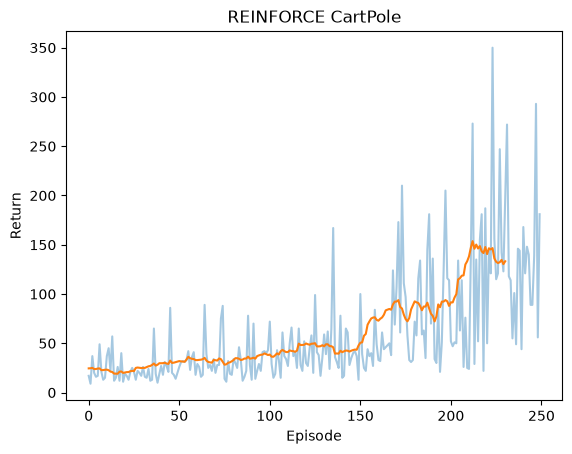

In [26]:
reinforce_model,reinforce_scores=train_reinforce(episodes=250)
plt.plot(reinforce_scores,alpha=.4)
if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
plt.title('REINFORCE CartPole');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

# **4. Actor-Critic**
```
1. 캐릭터가 한 판을 끝까지 플레이함
2. 어떤 행동을 했고, 어떤 보상을 받았는지 기록
3. 그 시점 이후 얻은 보상(리턴)을 이용해 행동 확률을 조정
```

- 위 내용이  REINFORCE 핵심
- 성공에 이르는 과정의 행동들을 학습에 반영. 예) 5번 점프하고 스테이지를 모두 클리어 함
- 한 판이 끝나야 업데이트하는 기본 형은 보상 변동이 커서 학습이 불안정할 수 있음
- 잘했는지 판단하는 기준이 부족 -> Actor-Critic의 등장

- Actor: 지금 어떤 행동을 할지 정함. 예) 점프 70%, 대기 30%
- Critic: 현재 상황이 앞으로 얼마나 유리한지 평가. 예) V(s)=5
> 예상보다 결과가 좋으면 -> 선택한 행동의 확률을 높이는 학습 신호

> 예상보다 결과가 나쁘면 -> 선택한 행동의 확률을 낮추는 학습 신호

> Critic의 예측은 정답이 아니라 학습 중이 추정치. 평가도 틀릴 수 있음


```
장애물 피하기 게임
1. 캐릭터 앞에 장애물이 나타남. (state, 상태)
2. Actor가 점프 70%, 대기 30%를 출력하고 행동을 하나 뽑음. (Policy, 정책)
3. Critic은 현재 상황에서 앞으로 얻을 할인된 보상의 기대값을 예측함. 예: V(s) = 4
4. 실제로 행동한 뒤 보상 r과 다음 상태 s'를 관찰함
5. Critic의 새 예측을 이용해 TD 오차 δ를 계산하고, Actor와 Critic을 각각 학습
```

> Critic이 정답을 아는 것은 아님. Critic도 경험을 통해 예측을 고쳐 나감

1. Actor의 출력
- 상태 s에서 행동 a를 선택할 확률
- 확률 70%라는 것은 무조건 점프한다는 뜻이 아님
- DQN의 Q(s, a)는 행동별 가치, Actor의 π(a|s)는 행동별 확률이므로 서로 다름

2. Critic의 출력
- 상태 가치 V(s)를 출력 
- 현재 상태에서 정책을 따를 때 앞으로 얻을 할인된 보상의 기대값


$$
\delta = r + \gamma(1-done)V(s') - V(s)
$$
$\delta$는 TD 오차. 새로 계산한 TD 목표 - Critic이 이전에 예측한 현재 가치

- 게임이 끝나지 않았다면(done=0) $δ = r + γ(1 − done)V(s′) − V(s)$
- 게임이 끝났다면(done=1) δ = r - V(s)

```
게임이 아직 끝나지 않았고 아래와 내용을 참고
- 현재 가치 V(s) = 4
- 점프 직후 보상 r = 1
- 다음 상태 가치 V(s') = 6
- 할인율 γ = 0.9
- done = 0
```

- TD 목표 = $r + γV(s')$ = 6.4
- $δ$ = 6.4 - 4 = 2.4
> Critic이 예상한 4보다 TD 목표가 6.4가 높음. Actor는 방금 선택한 점프의 확률을 높이는 방향으로, Critic은 4라는 예측을 6.4에 가깝게 만다는 방향으로 학습


> 2.4는 확률이 2.4% 증가한다는 뜻은 아님. 실제 변화량은 신경망과 학습률에 따라 달라짐. Critic의 예측이 부정확할 수 있으므로 정답이 아니라 학습 신호

$$
L_{actor}=-\log\pi(a|s)\,\mathrm{stopgrad}(\delta)
$$

\log\pi(a|s) 선택한 행동의 확률
로그는 미분해서 계산 쉽게하려고
맨 앞 -는 

$$
L_{critic}=(V(s)-\mathrm{stopgrad}(r+\gamma(1-done)V(s')))^2
$$
V(s)는 가치, V(s')는 다음 상태 가치, 제곱하는 이유는 계산한 후에 실제값이 0으로 줄어들면 안되기 때문에


- stopgrad는 해당 값을 상수처럼 취급하여 그 경로로 역전파하지 않는다는 의미(detach(), torch.no_grad())

In [27]:
def td_error(value, reward, next_value, gamma=0.9, done=False):
    target = reward + gamma * (1 - int(done)) * next_value
    delta = target - value
    return target, delta

cases = [
    ("예상보다 좋음", 4, 1, 6, 0.9, False),
    ("예상보다 나쁨", 5, 2, 4, 0.5, False),
    ("종료 상태", 4, 1, 100, 0.9, True),
]
for name, v, r, next_v, gamma, done in cases:
    target, delta = td_error(v, r, next_v, gamma, done)
    print(f"{name}: TD 목표={target:.2f}, 현재 예측={v:.2f}, δ={delta:+.2f}")

예상보다 좋음: TD 목표=6.40, 현재 예측=4.00, δ=+2.40
예상보다 나쁨: TD 목표=4.00, 현재 예측=5.00, δ=-1.00
종료 상태: TD 목표=1.00, 현재 예측=4.00, δ=-3.00


In [28]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim = 4, n_actions=2):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, 128), 
            nn.Tanh()
        )
        self.actor = nn.Linear(128, n_actions)
        self.critic = nn.Linear(128, 1)

    def forward(self, x):
        h = self.body(x)
        return self.actor(h), self.critic(h). squeeze(-1)

In [29]:
ac_demo = ActorCriticNet().to(DEVICE)
lg, val = ac_demo(state_demo)
print('Actor logits: ', lg.shape, 'Critic V(s): ', val.shape)

Actor logits:  torch.Size([1, 2]) Critic V(s):  torch.Size([1])


In [30]:
import torch.nn.functional as F


ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr = 1e-3)
s = torch.zeros((1, 4), device=DEVICE)
s2 = torch.tensor([[0.02, 0.1, -0.03, 0.02]], device=DEVICE)

logits, value = ac(s)
dist = Categorical(logits=logits)
a = dist.sample()

with torch.no_grad():
    _, next_value = ac(s2)
    td_target = torch.tensor([1.0], device=DEVICE) + 0.99*next_value

advantage = td_target - value
actor_loss = -(dist.log_prob(a) * advantage.detach()).mean()
critic_loss = F.mse_loss(value, td_target)
# 0.5는 두 손실의 상대 가중치
loss = actor_loss + 0.5 * critic_loss
opt.zero_grad
loss.backward()
opt.step()

print('선택 행동:',a.item(),'TD 목표:',td_target.item(),'Advantage:',advantage.item(),'Loss:',loss.item())

선택 행동: 0 TD 목표: 1.0370668172836304 Advantage: 0.9830765724182129 Loss: 1.2196718454360962


### Advantage
- A(s, a)= Q(s, a) - V(s)
- Q: 특정 행동의 예상 가치
- V: 그 상태에서 정책을 따를 때의 평균적인 예상 가치
- Actor-Critic 코드에서는 `r + γV(s') - V(s)` 같은 TD 오차를 Advantage의 추정값으로 사용
- Advantage는 받은 보상 r이 아님. 기대와 비교한 차이


In [31]:
expected = 5.0
for name, estimated_action_value in [('점프', 8.0), ('대기', 3.0)]:
    advantage = estimated_action_value - expected
    print(f'{name}: 행동가치 {estimated_action_value:.1f} - 상태가치 {expected:.1f} = Advantage {advantage:+.1f}')

점프: 행동가치 8.0 - 상태가치 5.0 = Advantage +3.0
대기: 행동가치 3.0 - 상태가치 5.0 = Advantage -2.0


### REINFORCE Cartpole을 Actor-Critic으로 변경
- REINFORCE는 에피소드가 끝난 뒤 할인 리턴을 계산했지만, Actor-Critic은 매 스텝 TD 오차로 업데이트
- PolicyNet 대신 Actor의 logits 2개 + Critic의 상태 가치 1개를 출력하는 ActorCriticNet을 사용
- 학습 보상 곡선을 REINFORCE와 비교함

1. ActorCriticNet을 이용해서 행동 확률과 상태 가치 V(s)를 출력
2. Categorical(logits = logits)로 행동을 샘플링하고 환경에서 한 스텝을 실행
3. 1250개 에피소드 동안 학습하고, 각 에피소드 보상과 최근 20회 이동 평균을 그림
4. 이미 학습한 reinforce_scores와 두 학습 곡선을 비교


In [32]:
# # 내가 한 거

# def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr = 1e-3):
#     torch.manual_seed(seed)
#     env = gym.make('CartPole-v1')

#     ac = ActorCriticNet().to(DEVICE)
#     opt = optim.Adam(ac.parameters(), lr = 1e-3)
    
#     scores = []

#     for ep in range(episodes):
#         state, _ = env.reset(seed = seed + ep)
#         logps = []
#         rewards = []

#         for t in range(500):
#             s = torch.zeros((1, 4), device=DEVICE)
#             s2 = torch.tensor([[0.02, 0.1, -0.03, 0.02]], device=DEVICE)

#             logits, value = ac(s)
#             dist = Categorical(logits=logits)
#             a = dist.sample()

#             with torch.no_grad():
#                 _, next_value = ac(s2)
#                 td_target = torch.tensor([1.0], device=DEVICE) + 0.99*next_value

#             next_state, rewards, terminated, truncated, _ = env.step(int(a.item()))

#             advantage = td_target - value
#             actor_loss = -(dist.log_prob(a) * advantage.detach()).mean()
#             critic_loss = F.mse_loss(value, td_target)

#             if terminated or truncated: break

#             loss = actor_loss + 0.5 * critic_loss

#             opt.zero_grad()
#             loss.backward()
#             opt.step()
#             scores.append(sum(rewards))
#             state = next_state
        
#     env.close()
#     return ac, scores


# reinforce_model,reinforce_scores=train_reinforce(episodes=250)
# plt.plot(reinforce_scores,alpha=.4)
# if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
# plt.title('REINFORCE CartPole');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

In [33]:
# 강사님
def train_actor_critic_answer(episodes=250, seed=2026, gamma=0.9, lr=2e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    model = ActorCriticNet().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        score = 0.0
        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x) # Actor logits, Critic V(s)
            dist = Categorical(logits=logits)
            action = dist.sample() # 0: 왼쪽, 1: 오른쪽
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            loss = actor_loss + 0.5 * critic_loss

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            score += float(reward)
            state = next_state
            if terminated or truncated:
                break

        scores.append(score)
        if (ep + 1) % 30 == 0:
            print(f'Actor-Critic {ep + 1} / {episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return model, scores

In [34]:
# # 강사님 주석
# def train_actor_critic_answer(episodes=250, seed=2026, gamma=0.99, lr=7e-4):
#     torch.manual_seed(seed)
#     env = gym.make('CartPole-v1')
#     model = ActorCriticNet().to(DEVICE) # Actor-Critic 모델 생성
#     optimizer = optim.Adam(model.parameters(), lr=lr)
#     scores = []

#     for ep in range(episodes):
#         state, _ = env.reset(seed=seed + ep)
#         score = 0.0
#         for t in range(500):
#             x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
#             logits, value = model(x) # Actor: 행동 점수(logits), Critic: 현재 상태 가치 V(s)
#             dist = Categorical(logits=logits) # Actor의 행동 점수를 확률분포로 변환
#             action = dist.sample() # 확률에 따라 행동 선택 (0: 왼쪽, 1: 오른쪽)
#             next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

#             # Critic의 TD Target 계산: r + γV(s')
#             with torch.no_grad():
#                 nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
#                 _, next_value = model(nx) # 다음 상태의 가치 V(s')
#                 td_target = torch.tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

#             delta = td_target - value # TD 오차: 실제 목표 가치 - 예측 가치
#             actor_loss = -(dist.log_prob(action) * delta.detach()).mean() # TD 오차를 이용해 Actor 정책 학습
#             critic_loss = F.mse_loss(value, td_target) # Critic의 가치 예측 오차 계산
#             loss = actor_loss + 0.5 * critic_loss # Actor와 Critic 손실 결합

#             optimizer.zero_grad() # 기존 기울기 초기화
#             loss.backward() # 역전파로 기울기 계산
#             nn.utils.clip_grad_norm_(model.parameters(), 1.0) # 기울기 폭발 방지
#             optimizer.step() # 모델 가중치 업데이트

#             score += float(reward)
#             state = next_state
#             if terminated or truncated: # 에피소드 종료 조건 확인
#                 break

#         scores.append(score)
#         if (ep + 1) % 30 == 0:
#             print(f'Actor-Critic {ep + 1} / {episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

#     env.close()
#     return model, scores

Actor-Critic 30 / 250 | 최근 20회 평균 11.5
Actor-Critic 60 / 250 | 최근 20회 평균 50.0
Actor-Critic 90 / 250 | 최근 20회 평균 48.2
Actor-Critic 120 / 250 | 최근 20회 평균 63.2
Actor-Critic 150 / 250 | 최근 20회 평균 68.1
Actor-Critic 180 / 250 | 최근 20회 평균 54.0
Actor-Critic 210 / 250 | 최근 20회 평균 57.0
Actor-Critic 240 / 250 | 최근 20회 평균 75.1


c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44540 (\N{HANGUL SYLLABLE GEUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sa

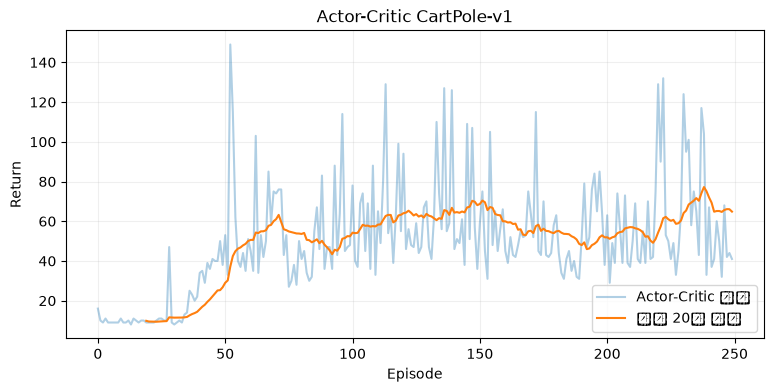

In [35]:
ac_cartpole_model, ac_cartpole_scores = train_actor_critic_answer()
plt.figure(figsize=(9, 4))
plt.plot(ac_cartpole_scores, alpha=0.35, label='Actor-Critic 보상')
if len(ac_cartpole_scores) >= 20:
    ma = np.convolve(ac_cartpole_scores, np.ones(20)/20, mode='valid')
    plt.plot(np.arange(19, len(ac_cartpole_scores)), ma, label='최근 20회 평균')
plt.xlabel('Episode'); plt.ylabel('Return'); plt.title('Actor-Critic CartPole-v1')
plt.legend(); plt.grid(alpha=0.2); plt.show()

c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu San

살아있음


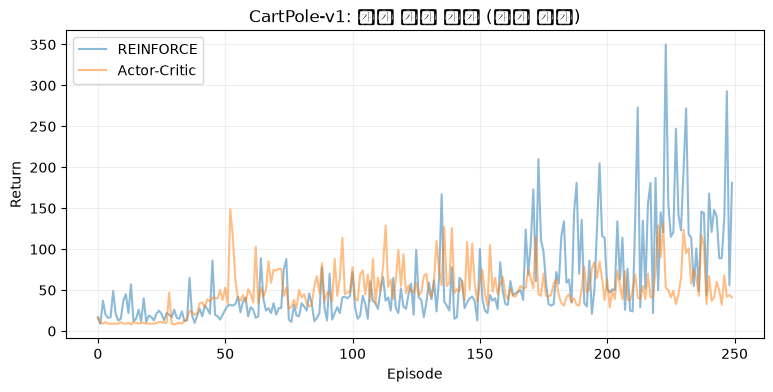

최근 20회 평균 REINFORCE: 133.2
최근 20회 평균 Actor-Critic: 64.8


In [36]:
if 'reinforce_scores' in globals():
    print('살아있음')
    plt.figure(figsize=(9, 4))
    plt.plot(reinforce_scores, alpha=0.5, label='REINFORCE')
    plt.plot(ac_cartpole_scores, alpha=0.5, label='Actor-Critic')
    plt.xlabel('Episode'); plt.ylabel('Return')
    plt.title('CartPole-v1: 학습 보상 비교 (단일 실행)')
    plt.legend(); plt.grid(alpha=0.2); plt.show()
    print('최근 20회 평균 REINFORCE:', round(float(np.mean(reinforce_scores[-20:])), 1))
    print('최근 20회 평균 Actor-Critic:', round(float(np.mean(ac_cartpole_scores[-20:])), 1))

### REINFORCE vs Actor-Critic 비교
1. REINFORCE
- 에피소드가 끝난 뒤 누적보상을 계산
- 실제 경험에서 얻은 리턴을 이용해 정책을 학습
- 리턴의 분산은 클 수 있지만, Critic의 가치 예측 오차에 영향을 받지 않음

2. Actor-Critic 
- 매 스탭 TD 오차를 계산
- Critic의 가치 예측을 이용해 Actor를 학습
- Critic의 예측이 부정확하면 Actor도 잘못된 방향으로 업데이트 될 수 있음

### Actor-Critic의 성능을 높이려면?
- 학습 횟수를 늘리고, 학습률을 낮춤

# **5. Actor-Critic을 이용한 달 착륙 AI개발**
Gymnasium을 이용하여 우주선이 스스로 엔진을 제어하고 안전하게 착륙하도록 학습하는 강화학습 시스템을 개발

### 1. 프로젝트 시나리오
- 달 표면에 착륙할 우주선은 처음에는 엔진을 언제 사용해야 하는지 알지 못함
- 너무 빠르게 하강하면 추락하고, 좌우 균형을 잡지 못하면 착륙 지점을 벗어날 수 있음
    - 우주선의 현재 위치와 속도를 분석
    - 우주선의 기울기와 회전 속도를 확인
    - 엔진을 사용하거나 사용하지 않는 행동을 선택
    - 행동 결과로 받은 보상을 이용하여 Actor와 Critic을 학습
    - 반복 학습을 통해 안전한 착륙을 시도

### 2. 개발 환경
- Gymnasium의 Lunarlander-v3 환경
```
python -m pip install "gymnasium[box2d]"
```

### 3. 상태 데이터
Lunarlander-v3는 매 스텝마다 8개의 숫자로 구성된 상태 벡터를 반환

```
0: 착륙 지점을 기준으로 한 좌우 위치
1: 착륙 지점을 기준으로 한 높이
2: 좌우 이동 속도
3: 상하 이동 속도
4: 우주선이 기울어진 각도
5: 우주선의 회전 속도
6: 왼쪽 착륙 다리가 지면에 닿았는지(0: 닿지않음, 1: 닿았음)
7: 오른쪽 착륙 다리가 지면에 닿았는지(0: 닿지않음, 1: 닿았음)
```

### 4. 행동 데이터(Action)

```
0: 엔진 사용 안 함: 중력 등에 따라 자연스럽게 이동
1: 왼쪽 보고 엔진: 우주선의 자세와 이동에 영향을 줌
2: 주 엔진: 주로 하강 속도를 제어하는 데 사용
3: 오른쪽 보조 엔진: 우주선의 자세와 이동에 영향을 줌
```

### 5. 보상 데이터
- LunarLander는 단순히 착륙 성공과 실패만 평가하지 않음
- 착륙 지점까지의 거리, 속도, 기울기, 착륙 다리 접촉, 엔진 사용량 등을 함께 고려
    - 착륙 지점에 가까워짐
    - 이동 속도가 줄어듦
    - 우주선의 기울기가 커짐
    - 착륙 다리 접촉
    - 주 엔진 사용
    - 보조 엔진 사용
    - 추락: -100
    - 안전한 착륙: 100

```
이렇게 설치하고 진행하면 시각화 할 수 있음  
python -m pip install swig
python -m pip install "gymnasium[box2d]"


probe = gym.make('CartPole-v1', render_mode="human") 
```

In [37]:
class ActorCriticNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(8, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU()
        )

        self.actor = nn.Linear(128, 4) # 행동 4개의 점수 출력
        self.critic = nn.Linear(128, 1) # 상태 가치 V(s) 출력

    def forward(self, x):
        x = self.shared(x)
        logits = self.actor(x)
        value = self.critic(x)

        return logits, value

In [38]:
import gymnasium as gym

env = gym.make("LunarLander-v3")  # , render_mode = "human"
state, info = env.reset(seed=2026)

print("상태:", state)
print("상태 크기:", env.observation_space.shape)
print("행동 개수:", env.action_space.n)


total_reward = 0

for step in range(1000):
    action = env.action_space.sample() # 0~3 중 하나의 행동을 무작위 선택

    next_state, reward, terminated, truncated, info = env.step(action) # 행동 실행

    total_reward += reward # 보상 누적
    state = next_state # 다음 상태로 갱신

    if terminated or truncated: # 착륙, 추락 또는 시간 제한으로 종료
        print("실행 횟수:", step + 1)
        print("총 보상:", total_reward)
        break

env.close()

상태: [ 0.00216942  1.4164361   0.21971932  0.24514917 -0.00250698 -0.04976973
  0.          0.        ]
상태 크기: (8,)
행동 개수: 4
실행 횟수: 115
총 보상: -70.05989097318073


In [39]:
# import gymnasium as gym
# import matplotlib.pyplot as plt

# env = gym.make("LunarLander-v3", render_mode="rgb_array")
# state, info = env.reset(seed=2026)

# frame = env.render()
# plt.imshow(frame)
# plt.axis("off")
# plt.show()

# env.close()

In [40]:
# # 내 코드
# import gymnasium as gym
# import numpy as np
# import torch
# import torch.nn as nn
# import torch.optim as optim
# import matplotlib.pyplot as plt
# from torch.distributions import Categorical

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# # 1. Actor-Critic 신경망
# class ActorCriticNet(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.shared = nn.Sequential(
#             nn.Linear(8, 128),
#             nn.ReLU(),
#             nn.Linear(128, 128),
#             nn.ReLU(),
#         )
#         self.actor = nn.Linear(128, 4)   # 행동 4개의 점수(logits)
#         self.critic = nn.Linear(128, 1)  # 상태 가치 V(s)

#     def forward(self, x):
#         x = self.shared(x)
#         return self.actor(x), self.critic(x)


# # 2. 화면으로 보여주는 함수 (학습 중 데모 / 최종 평가 공용)
# def play(model, episodes=3, seed=3000, greedy=True):
#     env = gym.make("LunarLander-v3", render_mode="human")
#     model.eval()
#     results = []

#     for ep in range(episodes):
#         state, _ = env.reset(seed=seed + ep)
#         total_reward = 0.0

#         for _ in range(1000):
#             x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
#             with torch.no_grad():
#                 logits, _ = model(x)
#                 if greedy:
#                     action = torch.argmax(logits, dim=-1).item()
#                 else:
#                     action = Categorical(logits=logits).sample().item()

#             state, reward, terminated, truncated, _ = env.step(action)
#             total_reward += reward
#             if terminated or truncated:
#                 break

#         results.append(total_reward)
#         print(f"  [화면 테스트 {ep+1}] 총 보상: {total_reward:.2f}")

#     env.close()
#     model.train()
#     return results


# # 3. Actor-Critic 학습 (n-step A2C)
# def train_actor_critic(
#     episodes=2000,
#     seed=2026,
#     gamma=0.99,
#     lr=3e-4,
#     n_steps=10,
#     demo_every=250,   # 이 에피소드마다 창을 띄워 보여줌 (0이면 끔)
# ):
#     torch.manual_seed(seed)
#     np.random.seed(seed)

#     env = gym.make("LunarLander-v3")  # 학습 중에는 렌더링 없음 (빠름)
#     model = ActorCriticNet().to(DEVICE)
#     optimizer = optim.Adam(model.parameters(), lr=lr)
#     scores = []

#     for ep in range(episodes):
#         state, _ = env.reset(seed=seed + ep)
#         total_reward = 0.0
#         log_probs, values, rewards, entropies = [], [], [], []

#         for _ in range(1000):
#             x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
#             logits, value = model(x)
#             dist = Categorical(logits=logits)
#             action = dist.sample()

#             next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
#             done = terminated or truncated

#             log_probs.append(dist.log_prob(action).squeeze())
#             values.append(value.squeeze())
#             entropies.append(dist.entropy().squeeze())
#             rewards.append(reward / 100.0)  # 보상 스케일링

#             total_reward += reward
#             state = next_state

#             # n스텝마다, 또는 에피소드가 끝나면 업데이트
#             if len(rewards) == n_steps or done:
#                 if terminated:
#                     R = torch.tensor(0.0, device=DEVICE)
#                 else:
#                     with torch.no_grad():
#                         nx = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
#                         _, nv = model(nx)
#                         R = nv.squeeze()

#                 returns = []
#                 for r in reversed(rewards):
#                     R = r + gamma * R
#                     returns.append(R)
#                 returns.reverse()

#                 returns = torch.stack(returns)
#                 values_t = torch.stack(values)
#                 log_probs_t = torch.stack(log_probs)
#                 entropies_t = torch.stack(entropies)

#                 advantage = returns - values_t

#                 actor_loss = -(log_probs_t * advantage.detach()).mean()
#                 critic_loss = 0.5 * advantage.pow(2).mean()
#                 loss = actor_loss + critic_loss - 0.01 * entropies_t.mean()

#                 optimizer.zero_grad()
#                 loss.backward()
#                 nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
#                 optimizer.step()

#                 log_probs, values, rewards, entropies = [], [], [], []

#             if done:
#                 break

#         scores.append(total_reward)

#         if (ep + 1) % 50 == 0:
#             print(f"Episode {ep+1}/{episodes} | 평균 보상: {np.mean(scores[-50:]):.2f}")

#         # 중간 데모: 창이 뜨고 1판을 보여준 뒤 닫힘
#         if demo_every and (ep + 1) % demo_every == 0:
#             print(f">>> {ep+1} 에피소드 시점 데모 (창이 작업 표시줄 뒤에 뜰 수 있어요)")
#             play(model, episodes=1, seed=9000 + ep)

#     env.close()
#     return model, scores


# # 4. 학습 실행
# model, scores = train_actor_critic()


# # 5. 학습 결과 시각화
# moving_avg = [np.mean(scores[max(0, i - 49): i + 1]) for i in range(len(scores))]

# plt.figure(figsize=(10, 5))
# plt.plot(scores, alpha=0.3, label="Episode Reward")
# plt.plot(moving_avg, label="50 Episode Average")
# plt.axhline(200, color="r", linestyle="--", label="Solved (200)")
# plt.xlabel("Episode")
# plt.ylabel("Reward")
# plt.title("Actor-Critic LunarLander-v3")
# plt.legend()
# plt.grid()
# plt.show()


# # 6. 최종 평가 (화면으로 확인)
# print("=== 최종 평가 ===")
# results = play(model, episodes=5, seed=3000)
# print(f"평균 보상: {np.mean(results):.2f}")

# 강사님

In [45]:
# continuous = False
env = gym.make("LunarLander-v3", continuous = False)
state, info = env.reset(seed=2026)
print('상태 공간: ', env.observation_space)
print("행동 공간: ", env.action_space)
print('상태 shape: ', state.shape, "| dtype: ", state.dtype)
print("행동 수: ", env.action_space.n)


상태 공간:  Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
행동 공간:  Discrete(4)
상태 shape:  (8,) | dtype:  float32
행동 수:  4


### MDP의 구성
- 상태 s: 우주선 위치, 속도, 기울기, 착륙 다리 접촉
- 행동 a: 네 가지 엔진 선택
- 보상 r: 착륙 성공, 안정성, 연료 사용 등의 결과
- 전이 p: 물리 시뮬레이터가 행동에 따라 다음 상태를 계산
- 할인률 γ: 미래 보상을 현재 보상에 얼마나 반영할지 결정

### Actor와 Critic의 역할
- Actor는 π(a|s)라는 정책을 학습. "이 상태에서 각 행동을 얼마나 자주 선택할까?"를 결정
- Critic은 V(s)를 학습. "현재 상태에서 앞으로 받을 할인 보상은 얼마나 될까?"를 예측

$$
y_t=r_{t+1}+\gamma(1-\mathrm{terminated})V(s_{t+1})
$$

- $r$: 이번 행동으로 실제 받은 보상
- γ V(s'): 다음 상태에서 앞으로 받을 보상에 대한 현재 추정
- terminated=True: 다음 상태의 가치를 더하지 않음

### TD 오차(델타)

$$
\delta_t=y_t-V(s_t)
$$

- δ>0: Critic의 예상보다 실제 한 스텝 결과가 좋음 > 선택한 행동을 강화할 신호
- δ<0: 예상보다 나쁨 > 선택한 행동의 확률을 낮출 신호

> Critic이 틀릴 수도 있기 때문에 δ는 완벽한 정답이 아님

### Actor Loss
$$
L_{actor}=-\log\pi(a_t|s_t)\,\mathrm{stopgrad}(\delta_t)
$$

> log_prob(action)은 실제로 선택한 행동의 로그 확률. delta.detach()는 actor가 critic 의 TD 오차를 역전파 경로로 직접 바꾸지 못하게 막음

### Critic Loss
$$
L_{critic}=(V(s_t)-\mathrm{stopgrad}(y_t))^2
$$
> 현재 가치 예측이 TD 목표에 가까워지도록 평균제곱오차(MSE)를 최소화

### 전체 Loss
$$
L=L_{actor}+\beta L_{critic}-\eta H(\pi(\cdot|s))
$$
- β: Critic 손실의 비중
- η: 엔트로피 보너승의 비중
- H: 정책의 불확실성. 지나친 조기 확신을 억제할 때 사용

> 전체 손실 L은 액터 손실에 베타 곱하기 크리틱 손실을 더하고, 에타 곱하기 엔트로피 에이치를 뺀 값

> 손실을 더하는 이유는 두 손실을 통해 공통 신경망을 포함한 파라미터를 함께 업데이트하기 때문

In [46]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, x):
        features = self.body(x)
        logits = self.actor(features)
        value = self.critic(features).squeeze(-1)
        return logits, value

In [57]:
model_test = ActorCriticNet().to(DEVICE)
dummy = torch.randn(3, 8, device=DEVICE)
logits, values = model_test(dummy)
print("입력: ", dummy.shape, "logits: ", logits.shape, "V(s): ", values.shape)
print("샘플 행동 확률: ", torch.softmax(logits, dim=-1).detach().cpu().numpy())

입력:  torch.Size([3, 8]) logits:  torch.Size([3, 4]) V(s):  torch.Size([3])
샘플 행동 확률:  [[0.26276964 0.22475564 0.22933249 0.28314224]
 [0.20123732 0.3019279  0.23051    0.26632473]
 [0.20385611 0.2635915  0.2606506  0.27190182]]


In [58]:
# 랜덤 정책 함수
def run_random_baseline(episodes=20, seed=1000):
    env = gym.make("LunarLander-v3", continuous=False)
    scores = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        env.action_space.seed(seed+ep)
        score = 0.0
        while True:
            action = env.action_space.sample()
            state, reward, terminated, truncated, _ = env.step(action)
            score += float(reward)
            if terminated or truncated:
                break
        scores.append(score)
    env.close()
    return scores

In [59]:
random_scores = run_random_baseline(episodes=20)
print("랜덤 정책 20회 평균: ", round(float(np.mean(random_scores)), 2))
print("최저/최고: ", round(min(random_scores), 2), round(max(random_scores), 2))

랜덤 정책 20회 평균:  -211.55
최저/최고:  -371.19 -76.22


### 한 스탭 안에서 처리할 일
1. state를 float32 텐서 (1, 8)로 변환
2. model(x)에서 logits와 value를 얻음
3. Categorical(logits=logits).sample()로 행동을 뽑음
4. env.step(action)으로 실제 행동을 실행
5. 다음 상태를 Critic에 넣어 next_value를 구함. torch.no_grad()로 TD 목표의 역전파를 차단
6. td_target = reward + gamma * (not terminated) * next_value를 계산
7. delta = td_target - value를 계산
8. actor_loss는 delta.detach()를 사용
9. critic_loss는 MSE로 현재 가치와 TD 목표의 차이를 줄임
10. 학습
11. terminated or truncated이면 에피소드를 끝냄

In [62]:
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [71]:
import time
import pandas as pd

# episodes: 학습할 에피소드 수
# seed: 난수 생성의 기준값
# gamma: 미래 보상의 할인율
# lr: 신경망 학습률
# hidden: 은닉층의 뉴런수
# max_steps: 한 에피소드에서 허용하는 최대 행동 횟수
# critic_coef: Critic 손실의 가중치
# entropy_coef: 탐색을 장려하는 엔트로피 보너스의 가중치
# print_every: 학습 결과를 출력하는 간격
def train_actor_critic(episodes=500, seed=2026, gamma=0.99, lr=3e-4, hidden=128, max_steps=1000, critic_coef=0.5, entropy_coef=0.0, print_every=50):
    set_seed(seed)
    env = gym.make("LunarLander-v3", continuous=False)
    env.action_space.seed(seed)
    model = ActorCriticNet(8, 4, hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scores, lengths, actor_losses, critic_losses, entropies = [], [], [], [], []
    start = time.time()

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        score, steps = 0.0, 0
        ep_actor, ep_critic, ep_entropy = [], [], []

        for t in range(max_steps):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x)
            dist = Categorical(logits=logits)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.as_tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            entropy = dist.entropy().mean()
            loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            score += float(reward)
            steps += 1
            state = next_state
            ep_actor.append(float(actor_loss.item()))
            ep_critic.append(float(critic_loss.item()))
            ep_entropy.append(float(entropy.item()))

            if terminated or truncated:
                break

        scores.append(score)
        lengths.append(steps)
        actor_losses.append(float(np.mean(ep_actor)))
        critic_losses.append(float(np.mean(ep_critic)))
        entropies.append(float(np.mean(ep_entropy)))

        if print_every and (ep+1) % print_every == 0:
            recent = np.mean(scores[-min(50,len(scores)):])
            print(f"Actor-Critic {ep+1:4d}/{episodes} | 최근 50회 평균 {recent:8.2f} | "
                f"이번 보상 {score:8.2f} | {time.time()-start:.0f}s")

    env.close()
    history = pd.DataFrame({
        "episode": np.arange(1, episodes+1), "reward": scores,
        "steps": lengths, "actor_loss": actor_losses,
        "critic_loss": critic_losses, "entropy": entropies,
    })
    return model, history

In [72]:
AC_EPISODES = 500
ac_model, ac_history = train_actor_critic(episodes=AC_EPISODES, seed=2026, gamma=0.99, lr=3e-4, entropy_coef=0.0)

Actor-Critic   50/500 | 최근 50회 평균  -529.25 | 이번 보상  -142.07 | 7s
Actor-Critic  100/500 | 최근 50회 평균  -437.89 | 이번 보상  -811.05 | 15s
Actor-Critic  150/500 | 최근 50회 평균  -201.38 | 이번 보상   -80.24 | 25s
Actor-Critic  200/500 | 최근 50회 평균   -52.03 | 이번 보상  -145.25 | 38s
Actor-Critic  250/500 | 최근 50회 평균  -141.89 | 이번 보상    30.99 | 99s
Actor-Critic  300/500 | 최근 50회 평균     9.50 | 이번 보상   183.43 | 130s
Actor-Critic  350/500 | 최근 50회 평균    -2.99 | 이번 보상    16.15 | 176s
Actor-Critic  400/500 | 최근 50회 평균    26.07 | 이번 보상   -18.17 | 208s
Actor-Critic  450/500 | 최근 50회 평균    74.23 | 이번 보상   302.45 | 229s
Actor-Critic  500/500 | 최근 50회 평균    49.86 | 이번 보상     9.16 | 246s


In [73]:
ac_history

,episode,reward,steps,actor_loss,critic_loss,entropy
0,1,-13.035850,112,-0.429048,102.729744,1.208724
1,2,-307.481730,91,-3.400514,111.732093,0.731227
2,3,-484.663361,122,-2.257645,94.618944,0.981540
3,4,-514.041435,95,-1.898803,124.672576,0.724872
4,5,-611.482090,87,-4.057433,136.360960,0.835105
...,...,...,...,...,...,...
495,496,248.863974,408,0.078364,33.101247,0.430975
496,497,86.924938,781,-0.101528,13.633300,0.588545
497,498,219.237030,424,0.558439,30.363398,0.542342
498,499,33.967237,203,-0.062554,47.661177,0.505399


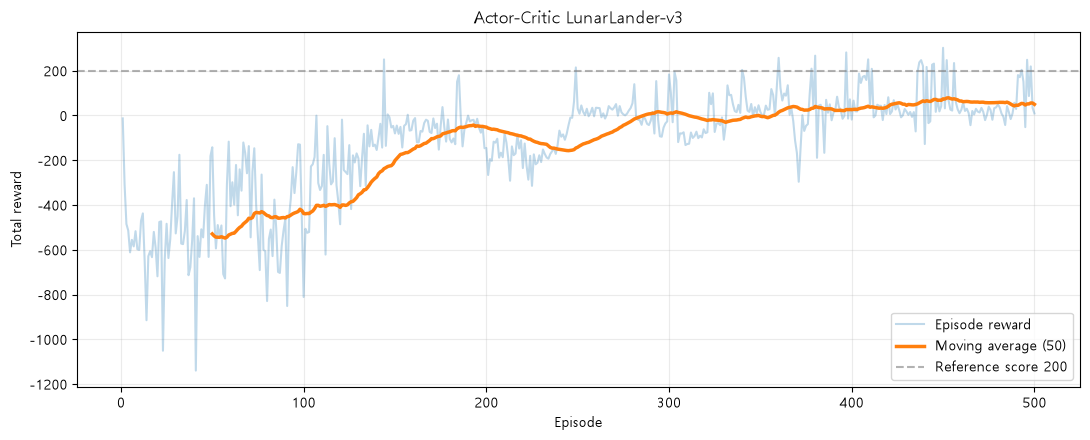

처음 50회 평균: -529.25
마지막 50회 평균: 49.86
전체 평균: -120.58
최고 에피소드 보상: 302.45
마지막 50회 평균 스텝: 261.7


In [77]:
def moving_average(values, window=50):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return np.array([]), np.array([])
    return np.arange(window, len(values)+1), np.convolve(values, np.ones(window)/window, mode="valid")

def plot_training(history, title="Actor-Critic LunarLander-v3", window=50):
    x = history["episode"].to_numpy()
    y = history["reward"].to_numpy()
    xx, yy = moving_average(y, window)
    plt.figure(figsize=(11,4.5))
    plt.plot(x, y, alpha=0.28, label="Episode reward")
    if len(xx):
        plt.plot(xx, yy, linewidth=2.5, label=f"Moving average ({window})")
    plt.axhline(200, linestyle="--", color="gray", alpha=0.6, label="Reference score 200")
    plt.xlabel("Episode"); plt.ylabel("Total reward"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

plot_training(ac_history)
print("처음 50회 평균:", round(ac_history.reward.head(50).mean(), 2))
print("마지막 50회 평균:", round(ac_history.reward.tail(50).mean(), 2))
print("전체 평균:", round(ac_history.reward.mean(), 2))
print("최고 에피소드 보상:", round(ac_history.reward.max(), 2))
print("마지막 50회 평균 스텝:", round(ac_history.steps.tail(50).mean(), 1))

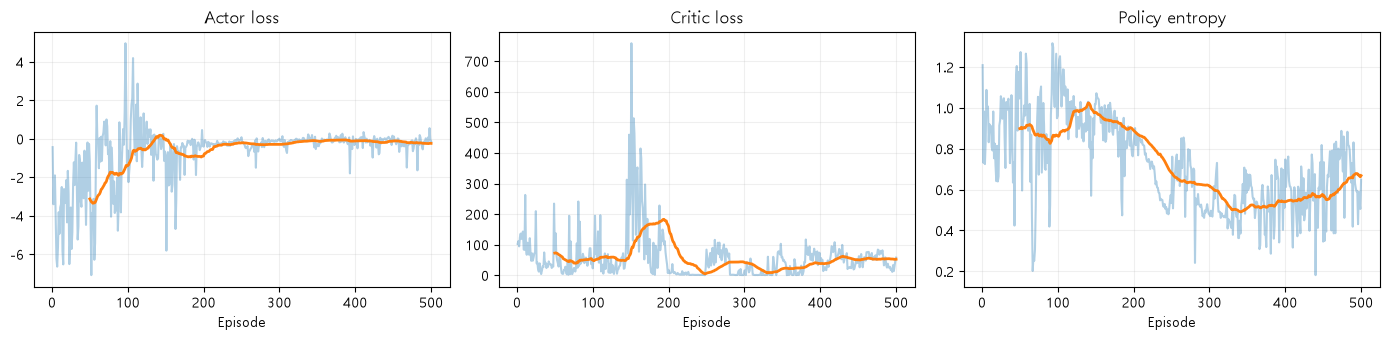

In [78]:
fig, axes = plt.subplots(1, 3, figsize=(14,3.5))
for ax, col, title in zip(axes, ["actor_loss", "critic_loss", "entropy"],
                        ["Actor loss", "Critic loss", "Policy entropy"]):
    ax.plot(ac_history.episode, ac_history[col], alpha=0.35)
    xx, yy = moving_average(ac_history[col], 50)
    if len(xx): ax.plot(xx, yy, linewidth=2)
    ax.set_title(title); ax.set_xlabel("Episode"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()